# Pengaturan Lingkungan (Environment Setup)

In [1]:
import numpy as np
import pandas as pd
%pip install shap
%pip install lightgbm

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    roc_auc_score, average_precision_score,
    precision_score, recall_score, f1_score,
    confusion_matrix
)

import xgboost as xgb
import lightgbm as lgb
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

import warnings
warnings.filterwarnings("ignore")


[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: /opt/homebrew/opt/python@3.11/bin/python3.11 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: /opt/homebrew/opt/python@3.11/bin/python3.11 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


Memuat Dataset (Load Dataset)

In [2]:
DATA_PATH = "loan_data_2007_2014.csv"

df = pd.read_csv(DATA_PATH, low_memory=False)
df_raw = df.copy()
print("Raw shape:", df.shape)

Raw shape: (466285, 75)


# 1. Pemahaman Bisnis (Business Understanding)

## 1.1 Latar Belakang
Industri pinjaman (*lending*) menghadapi tantangan besar terkait risiko kredit (*credit risk*), di mana peminjam berpotensi gagal membayar kembali pinjamannya sehingga mengakibatkan kerugian finansial bagi institusi pemberi pinjaman. Penilaian risiko peminjam yang akurat sangat penting untuk menjaga kualitas portofolio sekaligus memastikan pertumbuhan bisnis yang berkelanjutan.

Sebagai bagian dari proyek ini, perusahaan pemberi pinjaman berupaya memanfaatkan data riwayat pengajuan pinjaman untuk membangun sistem prediktif yang mampu mengidentifikasi peminjam berisiko tinggi sebelum keputusan persetujuan pinjaman dibuat. Dengan memanfaatkan pendekatan berbasis data, perusahaan bertujuan meningkatkan proses pengambilan keputusan, menurunkan tingkat gagal bayar (*default rate*), dan mengoptimalkan strategi persetujuan pinjaman.

## 1.2 Masalah Bisnis
Proses evaluasi kredit tradisional sering kali mengandalkan penilaian manual atau sistem berbasis aturan (*rule-based*) yang mungkin gagal menangkap hubungan yang kompleks di dalam data peminjam. Keterbatasan ini dapat memicu dua risiko utama:

1. Menyetujui peminjam berisiko tinggi, sehingga meningkatkan kerugian akibat gagal bayar (*default*).
2. Menolak peminjam potensial yang baik, sehingga mengurangi peluang pendapatan bisnis.

Oleh karena itu, masalah bisnis utama yang diselesaikan dalam proyek ini adalah:

**Bagaimana perusahaan pemberi pinjaman dapat memprediksi risiko kredit peminjam secara akurat untuk mendukung keputusan persetujuan pinjaman sekaligus menyeimbangkan pengendalian risiko dan pertumbuhan bisnis?**

## 1.3 Tujuan Proyek
Tujuan dari proyek ini adalah mengembangkan model prediksi risiko kredit secara menyeluruh (*end-to-end*) yang mampu mengklasifikasikan pemohon pinjaman ke dalam kategori berisiko rendah dan berisiko tinggi.

Secara spesifik, proyek ini bertujuan untuk:

- Membangun model *machine learning* untuk memprediksi probabilitas gagal bayar (*loan default*).
- Membandingkan beberapa algoritma guna mengidentifikasi model prediktif yang paling sesuai.
- Mengoptimalkan ambang batas keputusan (*decision threshold*) untuk mensimulasikan kebijakan pinjaman di dunia nyata.
- Memberikan wawasan yang dapat diinterpretasikan mengenai faktor-faktor utama yang memengaruhi risiko kredit.
- Menyajikan rekomendasi bisnis yang mendukung pengambilan keputusan persetujuan pinjaman berbasis data.

## 1.4 Dampak Bisnis
Sistem prediksi risiko kredit yang diusulkan memberikan beberapa manfaat potensial bagi perusahaan pemberi pinjaman:

- Pengurangan kerugian finansial akibat peminjam yang gagal bayar.
- Peningkatan konsistensi dan objektivitas dalam pengambilan keputusan persetujuan pinjaman.
- Peningkatan kemampuan dalam menyeimbangkan tingkat persetujuan (*approval rate*) dan risiko portofolio.
- Mendukung proses penilaian kredit yang dapat diskalakan dan terotomatisasi.

Dengan mengintegrasikan analitik prediktif ke dalam operasional pinjaman, perusahaan dapat bertransformasi dari manajemen risiko yang reaktif menuju pencegahan risiko yang proaktif.

## 1.5 Ruang Lingkup Proyek
Proyek ini berfokus pada prediksi risiko kredit menggunakan data historis pinjaman yang tersedia pada saat pengajuan pinjaman dilakukan. Hanya fitur-fitur yang diketahui sebelum persetujuan pinjaman yang digunakan untuk mencegah kebocoran data (*data leakage*) dan memastikan penerapan model yang realistis.

Variabel kinerja pasca-pinjaman, seperti hasil pembayaran cicilan dan atribut terkait pemulihan/penagihan (*recoveries*), dikecualikan dari pemodelan agar tetap relevan untuk implementasi di dunia nyata.

# 2. Metodologi Data Science

## 2.1 Gambaran Umum Metodologi

Proyek ini mengikuti kerangka kerja **CRISP-DM (Cross-Industry Standard Process for Data Mining)**, sebuah metodologi data science yang banyak diadopsi untuk menstrukturkan proyek analitik dari pemahaman bisnis hingga tahap penerapan (*deployment*).

CRISP-DM memastikan bahwa pengembangan model selaras dengan tujuan bisnis sembari mempertahankan alur kerja analitik yang sistematis dan dapat direproduksi.

## 2.2 Kerangka Kerja CRISP-DM

Kerangka kerja CRISP-DM terdiri dari enam fase utama:

1. **Pemahaman Bisnis (Business Understanding)**  
   Memahami tujuan organisasi dan menerjemahkan masalah bisnis ke dalam tugas-tugas data science.

2. **Pemahaman Data (Data Understanding)**  
   Mengeksplorasi karakteristik dataset, definisi fitur, dan distribusi data.

3. **Persiapan Data (Data Preparation)**  
   Membersihkan data, menangani nilai yang hilang (*missing values*), menghapus kebocoran data (*data leakage*), dan mentransformasikan fitur agar sesuai untuk pemodelan.

4. **Pemodelan (Modeling)**  
   Mengembangkan dan membandingkan algoritma machine learning untuk memprediksi risiko kredit.

5. **Evaluasi (Evaluation)**  
   Menilai performa model menggunakan metrik yang tepat dan mengoptimalkan ambang batas keputusan berdasarkan tujuan bisnis.

6. **Penerapan (Deployment)**  
   Merancang bagaimana model dapat diintegrasikan ke dalam sistem pengambilan keputusan pinjaman di dunia nyata.

## 2.3 Implementasi Metodologi dalam Proyek Ini

Penerapan CRISP-DM dalam proyek ini diringkas sebagai berikut:

| Fase CRISP-DM | Implementasi dalam Proyek |
|----------------|------------------------|
| Pemahaman Bisnis (*Business Understanding*) | Mendefinisikan tujuan prediksi risiko kredit |
| Pemahaman Data (*Data Understanding*) | Eksplorasi dataset dan analisis fitur |
| Persiapan Data (*Data Preparation*) | Pembersihan data, penanganan *leakage*, *encoding*, dan prapemrosesan |
| Pemodelan (*Modeling*) | *Benchmarking* algoritma menggunakan Logistic Regression, LightGBM, dan XGBoost |
| Evaluasi (*Evaluation*) | Perbandingan performa dan optimasi ambang batas (*threshold*) |
| Penerapan (*Deployment*) | Alur kerja *credit scoring* dan simulasi kebijakan pinjaman |

# 3. Pemahaman Data (Data Understanding)

## 3.1 Gambaran Umum Dataset

Dataset yang digunakan dalam proyek ini berisi riwayat data pengajuan pinjaman yang diperoleh dari sebuah perusahaan pembiayaan (*lending company*). Setiap catatan (*record*) merepresentasikan satu pinjaman yang disalurkan kepada peminjam beserta informasi demografis, finansial, dan data terkait kredit peminjam.

Dataset mencakup informasi yang mendeskripsikan karakteristik peminjam, atribut pinjaman, dan riwayat perilaku kredit. Variabel-variabel ini digunakan untuk menganalisis profil risiko peminjam dan mendukung pemodelan prediksi risiko kredit.

In [3]:
print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (466285, 75)


,Unnamed: 0,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,...,total_bal_il,il_util,open_rv_12m,open_rv_24m,max_bal_bc,all_util,total_rev_hi_lim,inq_fi,total_cu_tl,inq_last_12m
0,0,1077501,1296599,5000,5000,4975.0,36 months,10.65,162.87,B,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,1077430,1314167,2500,2500,2500.0,60 months,15.27,59.83,C,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2,1077175,1313524,2400,2400,2400.0,36 months,15.96,84.33,C,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,3,1076863,1277178,10000,10000,10000.0,36 months,13.49,339.31,C,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,4,1075358,1311748,3000,3000,3000.0,60 months,12.69,67.79,B,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Dataset ini berisi 466.285 data pinjaman dengan 75 fitur yang mendeskripsikan karakteristik peminjam, atribut pinjaman, dan informasi terkait kredit.

Setiap baris observasi mewakili satu aplikasi pinjaman yang diajukan ke platform pembiayaan. Dataset mencakup variabel numerik dan kategorikal yang menangkap kapasitas finansial, riwayat kredit, dan ketentuan pinjaman.

## 3.2 Struktur Data dan Tipe Fitur

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 466285 entries, 0 to 466284
Data columns (total 75 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   Unnamed: 0                   466285 non-null  int64  
 1   id                           466285 non-null  int64  
 2   member_id                    466285 non-null  int64  
 3   loan_amnt                    466285 non-null  int64  
 4   funded_amnt                  466285 non-null  int64  
 5   funded_amnt_inv              466285 non-null  float64
 6   term                         466285 non-null  object 
 7   int_rate                     466285 non-null  float64
 8   installment                  466285 non-null  float64
 9   grade                        466285 non-null  object 
 10  sub_grade                    466285 non-null  object 
 11  emp_title                    438697 non-null  object 
 12  emp_length                   445277 non-null  object 
 13 

Dataset ini berisi kombinasi variabel numerik dan kategorikal, mencakup karakteristik pinjaman, informasi pekerjaan peminjam, indikator riwayat kredit, dan status pembayaran pinjaman.

## 3.3 Pemahaman Variabel Target

In [5]:
df["loan_status"].value_counts()

loan_status
Current                                                224226
Fully Paid                                             184739
Charged Off                                             42475
Late (31-120 days)                                       6900
In Grace Period                                          3146
Does not meet the credit policy. Status:Fully Paid       1988
Late (16-30 days)                                        1218
Default                                                   832
Does not meet the credit policy. Status:Charged Off       761
Name: count, dtype: int64

Distribusi status pinjaman (*loan status*) menunjukkan bahwa sebagian besar pinjaman tergolong dalam kategori *Current* (sedang berjalan lancar) dan *Fully Paid* (lunas), sedangkan kondisi gagal bayar seperti *Charged Off*, *Default*, dan *Late Payments* (terlambat) terjadi lebih jarang.

Ketidakseimbangan ini mencerminkan kondisi nyata di industri pinjaman, di mana kasus gagal bayar relatif jarang terjadi dibandingkan dengan pinjaman yang lancar. Oleh karena itu, pemodelan risiko kredit memerlukan penanganan ketidakseimbangan kelas (*class imbalance*) secara hati-hati agar model dapat mengidentifikasi peminjam berisiko tinggi dengan akurat.

## 3.4 Definisi Label Risiko Kredit

Untuk memodelkan risiko kredit secara realistis, status pinjaman dikelompokkan ke dalam dua kategori:

### Good Loan (Pinjaman Baik)
- Fully Paid

### Bad Loan (Pinjaman Buruk / Berisiko)
- Charged Off
- Default
- Late (16–30 days)
- Late (31–120 days)

Pinjaman dengan status pembayaran yang belum pasti (ambigu) dikecualikan untuk memastikan batas klasifikasi yang tegas dan jelas.

## 3.5 Gambaran Umum Kategori Fitur

Fitur-fitur terkait pinjaman dapat dikategorikan sebagai berikut:

| Kategori Fitur | Deskripsi |
|------------------|-------------|
| Informasi Peminjam (*Borrower Information*) | Pekerjaan, pendapatan, status kepemilikan rumah |
| Atribut Pinjaman (*Loan Attributes*) | Jumlah pinjaman, suku bunga, tenor pinjaman |
| Riwayat Kredit (*Credit History*) | Keterlambatan pembayaran, tingkat utilisasi kredit |
| Informasi Rekening (*Account Information*) | Lini kredit dan total saldo |
| Status Akhir Pinjaman (*Loan Outcome*) | Status pembayaran pinjaman |

## 3.6 Relevansi Fitur terhadap Risiko Kredit
Variabel-variabel di dalam dataset mendeskripsikan berbagai aspek perilaku finansial peminjam dan karakteristik pinjaman yang relevan untuk penilaian risiko kredit.

**Atribut Pinjaman (*Loan Attributes*)**  
Fitur seperti jumlah pinjaman, suku bunga, dan tenor pinjaman mencerminkan ketentuan pinjaman dan penilaian risiko peminjam oleh pemberi pinjaman. Suku bunga yang lebih tinggi umumnya diasosiasikan dengan profil risiko peminjam yang dinilai lebih tinggi.

**Kapasitas Finansial Peminjam (*Borrower Financial Capacity*)**  
Variabel seperti pendapatan tahunan (*annual income*) dan rasio utang terhadap pendapatan (*debt-to-income ratio*) merepresentasikan kemampuan bayar peminjam. Peminjam dengan beban finansial yang lebih besar relatif terhadap pendapatannya memiliki kemungkinan gagal bayar yang lebih tinggi.

**Indikator Riwayat Kredit (*Credit History Indicators*)**  
Variabel terkait kredit seperti utilisasi kredit berulang (*revolving utilization*), jumlah tunggakan (*delinquencies*), dan riwayat lini kredit memberikan wawasan mengenai perilaku pinjaman dan kedisiplinan finansial di masa lalu.

**Informasi Pekerjaan dan Kepemilikan Aset (*Employment and Ownership Information*)**  
Lama bekerja (*employment length*) dan status kepemilikan rumah dapat mengindikasikan stabilitas keuangan dan keandalan pembayaran jangka panjang.

Secara kolektif, kelompok-kelompok fitur ini mendukung evaluasi risiko kredit secara menyeluruh.

## 3.7 Observasi Awal

Pemeriksaan awal terhadap dataset menunjukkan beberapa karakteristik penting:

- Dataset berisi variabel numerik dan kategorikal yang memerlukan prapemrosesan.
- Distribusi status pinjaman mengindikasikan adanya ketidakseimbangan kelas (*class imbalance*) antara peminjam baik dan buruk.
- Beberapa variabel memiliki nilai yang hilang (*missing values*) atau kategori dengan kardinalitas yang sangat tinggi.
- Variabel tertentu pasca-pinjaman berpotensi menimbulkan kebocoran data (*data leakage*) jika digunakan untuk prediksi.

Observasi ini menjadi panduan untuk penilaian kualitas data dan langkah prapemrosesan selanjutnya.

# 4. Penilaian Kualitas Data (Data Quality Assessment)

## 4.1 Gambaran Umum Kualitas Data

Sebelum membangun model prediktif, sangat penting untuk mengevaluasi kualitas dataset guna memastikan hasil analisis yang andal. Penilaian kualitas data bertujuan untuk mengidentifikasi potensi masalah seperti nilai yang hilang (*missing values*), catatan duplikat, ketidakkonsistenan tipe data, dan fitur yang dapat menimbulkan kebocoran data (*data leakage*).

Penanganan yang tepat terhadap masalah-masalah ini memastikan bahwa model yang dikembangkan mencerminkan skenario pemberian pinjaman yang realistis.

## 4.2 Analisis Nilai yang Hilang (Missing Values)

In [6]:
missing_summary = df.isnull().sum().to_frame("Missing Count")
missing_summary["Missing Percentage"] = (
    missing_summary["Missing Count"] / len(df)
) * 100

missing_summary.sort_values(
    by="Missing Percentage",
    ascending=False
).head(25)

,Missing Count,Missing Percentage
inq_last_12m,466285,100.000000
total_bal_il,466285,100.000000
dti_joint,466285,100.000000
verification_status_joint,466285,100.000000
annual_inc_joint,466285,100.000000
open_acc_6m,466285,100.000000
open_il_6m,466285,100.000000
open_il_12m,466285,100.000000
open_il_24m,466285,100.000000
mths_since_rcnt_il,466285,100.000000


Analisis nilai yang hilang menunjukkan bahwa beberapa variabel memiliki proporsi data hilang yang sangat tinggi. Sekelompok fitur, termasuk `max_bal_bc`, `open_rv_24m`, `inq_fi`, `open_il_24m`, dan variabel terkait lainnya, memiliki hampir 100% nilai hilang di seluruh observasi.

Fitur-fitur tersebut hampir tidak memberikan informasi yang dapat digunakan untuk pemodelan prediktif, sehingga tidak layak disertakan dalam analisis.

Selain itu, variabel seperti `mths_since_last_record`, `mths_since_last_major_derog`, dan `desc` mengandung proporsi nilai hilang yang substansial (melebihi 70%). Variabel-variabel ini mewakili informasi peminjam yang bersifat opsional atau tidak dilaporkan secara konsisten, yang dapat menimbulkan derau (*noise*) jika dipertahankan tanpa penanganan khusus.

Berdasarkan temuan ini:
- Fitur dengan nilai hilang mendekati 100% dihapus dari dataset.
- Fitur dengan proporsi *missing values* sangat tinggi dikecualikan karena keandalannya yang rendah.
- Variabel yang tersisa dengan tingkat *missing values* moderat akan ditangani menggunakan imputasi statistik pada fase persiapan data.

Strategi ini menjaga kualitas data sekaligus mempertahankan sinyal prediktif yang bermakna untuk pemodelan risiko kredit.

## 4.3 Catatan Duplikat (Duplicate Records)

In [7]:
df.duplicated().sum()

np.int64(0)

Pemeriksaan catatan duplikat menunjukkan tidak ada baris duplikat di dalam dataset. Hal ini mengonfirmasi bahwa setiap observasi merupakan pengajuan pinjaman yang unik, sehingga mencegah bias sampel selama pelatihan model.

## 4.4 Identifikasi Kebocoran Data (Data Leakage)

Kebocoran data (*data leakage*) terjadi ketika informasi yang belum tersedia pada saat persetujuan pinjaman justru digunakan dalam pelatihan model. Variabel seperti ini akan menaikkan performa model secara semu dan menghasilkan prediksi yang tidak realistis pada implementasi nyata.

Dalam pemodelan risiko kredit, hanya informasi yang sudah tersedia pada tahap pengajuan pinjaman yang boleh digunakan.

Variabel pasca-pinjaman berikut diidentifikasi sebagai potensi sumber kebocoran data:

| Fitur | Alasan Penghapusan |
|----------|-------------------|
| total_pymnt | Hanya diketahui setelah masa pembayaran berjalan |
| recoveries | Terjadi setelah peminjam mengalami gagal bayar (*default*) |
| last_pymnt_amnt | Informasi yang tercatat setelah pinjaman berjalan |
| collection_recovery_fee | Terkait erat dengan proses penagihan pasca-*default* |
| out_prncp | Sisa saldo pokok setelah pinjaman diterbitkan |
| last_credit_pull_d | Diperbarui setelah pinjaman disetujui |

## 4.5 Fitur dengan Kardinalitas Tinggi (High Cardinality)

In [8]:
df.nunique().sort_values(ascending=False).head(20)

Unnamed: 0                 466285
url                        466285
member_id                  466285
id                         466285
total_pymnt                351609
total_pymnt_inv            347659
total_rec_int              270249
tot_cur_bal                220690
emp_title                  205475
last_pymnt_amnt            198194
total_rec_prncp            172713
out_prncp_inv              141189
out_prncp                  135665
desc                       124435
title                       63098
revol_bal                   58142
installment                 55622
annual_inc                  31901
recoveries                  22773
collection_recovery_fee     20275
dtype: int64

Analisis kardinalitas tinggi dilakukan untuk mengidentifikasi fitur yang memiliki jumlah nilai unik sangat banyak, yang berpotensi berdampak buruk pada performa model setelah proses encoding.

Beberapa variabel seperti `Unnamed: 0`, `id`, `member_id`, dan `url` memiliki nilai unik pada hampir setiap baris observasi. Kolom-kolom ini hanya berfungsi sebagai pengenal (*identifier*) dan tidak mengandung informasi prediktif, sehingga dihapus dari proses pemodelan.

Selain itu, variabel berbasis teks seperti `emp_title`, `title`, dan `desc` memiliki kardinalitas yang sangat tinggi dan bervariasi karena diisi secara bebas oleh peminjam. Penerapan encoding pada fitur-fitur ini akan meningkatkan dimensionalitas data secara drastis serta menambah derau (*noise*), yang dapat memicu *overfitting*.

Lebih lanjut, sejumlah variabel berkardinalitas tinggi seperti `total_pymnt`, `recoveries`, `last_pymnt_amnt`, dan sisa saldo pokok pinjaman diidentifikasi sebagai atribut pasca-pinjaman. Karena variabel-variabel ini baru muncul setelah pinjaman berjalan, fitur tersebut memicu *data leakage* dan dihapus agar prediksi risiko kredit tetap realistis.

Menghapus fitur-fitur ini meningkatkan efisiensi komputasi sekaligus mempertahankan kemampuan generalisasi model.

## 4.6 Strategi Penanganan Kualitas Data

Berdasarkan penilaian kualitas data, tindakan penanganan yang diterapkan dirangkum sebagai berikut:

| Masalah yang Diidentifikasi | Strategi Penanganan | Justifikasi |
|------------------|-------------------|--------------|
| Nilai yang Hilang (*Missing Values*) | Imputasi / Penghapusan | Mempertahankan informasi yang dapat digunakan |
| Catatan Duplikat (*Duplicate Records*) | Dihapus (bila ada) | Mencegah bias pada sampel |
| Kebocoran Data (*Data Leakage*) | Penghapusan Fitur | Memastikan prediksi yang realistis di dunia nyata |
| Kardinalitas Tinggi (*High Cardinality*) | Penghapusan Fitur | Mengurangi dimensionalitas dan mencegah *overfitting* |

# 5. Analisis Eksplorasi Data (Exploratory Data Analysis - EDA)

## 5.1 Analisis Distribusi Target

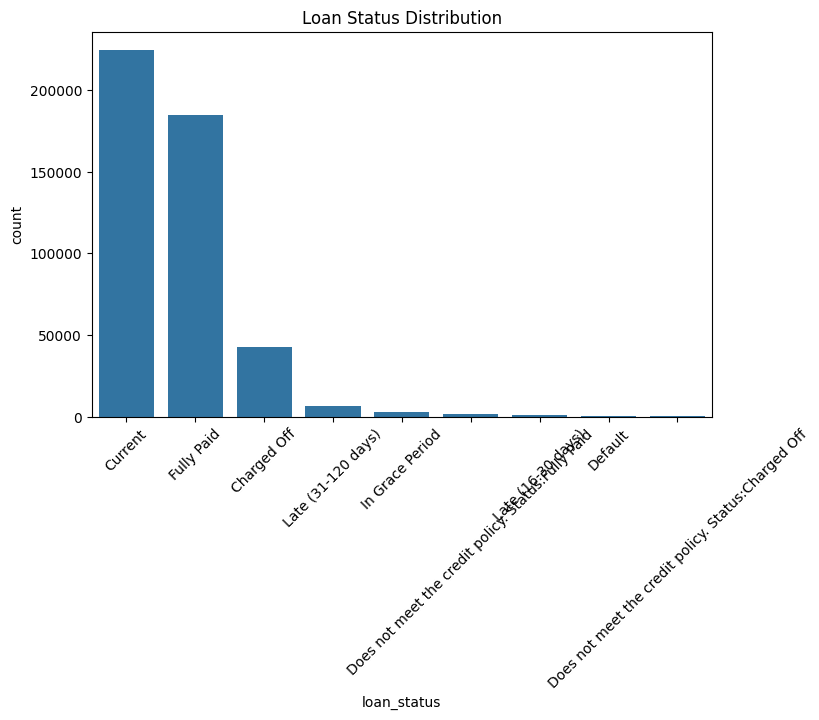

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,5))
sns.countplot(
    data=df,
    x="loan_status",
    order=df["loan_status"].value_counts().index
)

plt.xticks(rotation=45)
plt.title("Loan Status Distribution")
plt.show()

Distribusi hasil pinjaman menunjukkan bahwa mayoritas pinjaman berada pada kategori *Current* dan *Fully Paid*, sementara hasil terkait gagal bayar seperti *Charged Off*, *Default*, dan status keterlambatan pembayaran hanya mencakup proporsi observasi yang jauh lebih kecil.

Ketimpangan ini mencerminkan portofolio pinjaman di dunia nyata di mana peminjam yang lancar membayar jumlahnya jauh melebihi peminjam yang macet. Namun demikian, meskipun frekuensinya lebih rendah, kejadian gagal bayar merupakan risiko finansial utama bagi institusi pemberi pinjaman.

Oleh karena itu, pemodelan prediktif harus berfokus pada efektivitas dalam mengidentifikasi kelompok minoritas peminjam berisiko tinggi daripada sekadar memaksimalkan akurasi klasifikasi secara keseluruhan.

## 5.2 Peringkat Pinjaman (Loan Grade) dan Risiko Kredit

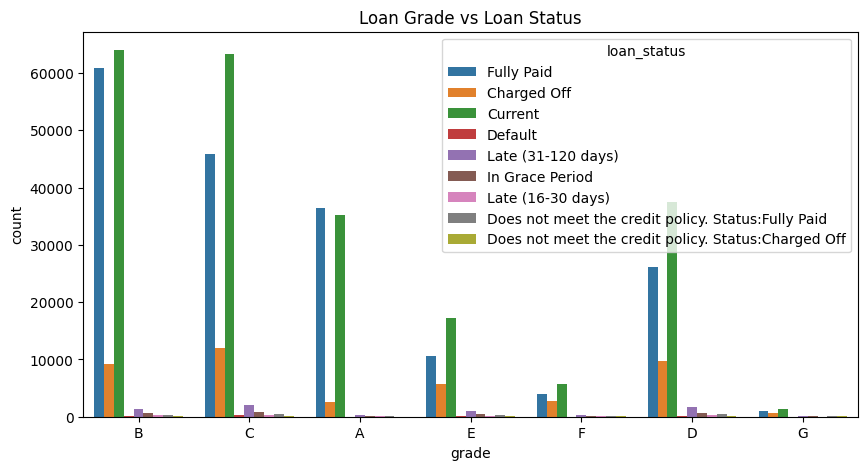

In [10]:
plt.figure(figsize=(10,5))

sns.countplot(
    data=df,
    x="grade",
    hue="loan_status"
)

plt.title("Loan Grade vs Loan Status")
plt.show()

Peringkat pinjaman (*loan grade*) merepresentasikan penilaian internal pemberi pinjaman terhadap kelayakan kredit peminjam. Visualisasi menunjukkan hubungan yang sangat jelas antara peringkat pinjaman dan status pengembalian pinjaman.

Peringkat berkualitas tinggi (A–B) didominasi oleh pinjaman yang lunas atau berstatus lancar, sedangkan peringkat yang lebih rendah (D–G) menunjukkan proporsi pinjaman *charged-off* dan *default* yang jauh lebih tinggi.

Pola ini mengonfirmasi bahwa penentuan peringkat pinjaman secara efektif menangkap segmentasi risiko peminjam dan diharapkan menjadi fitur prediktif yang kuat dalam model risiko kredit.

## 5.3 Suku Bunga (Interest Rate) dan Risiko Kredit

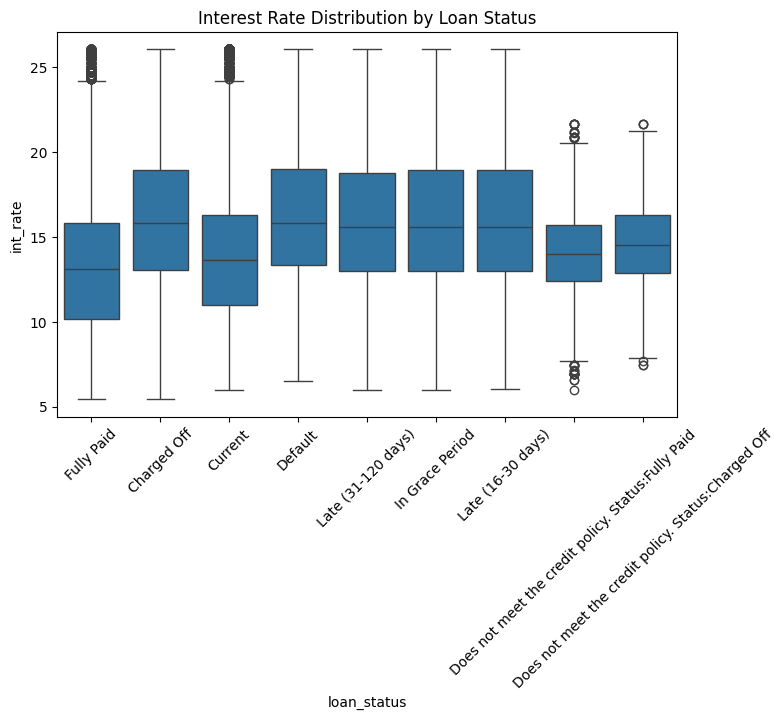

In [11]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x="loan_status",
    y="int_rate"
)

plt.xticks(rotation=45)
plt.title("Interest Rate Distribution by Loan Status")
plt.show()

Distribusi suku bunga bervariasi secara nyata di berbagai status pinjaman. Pinjaman yang mengalami gagal bayar atau kesulitan pengembalian cenderung memiliki median suku bunga yang lebih tinggi dibandingkan dengan pinjaman yang lunas.

Observasi ini mencerminkan praktik penetapan harga berbasis risiko (*risk-based pricing*) di industri pinjaman, di mana peminjam yang dianggap lebih berisiko akan dikenakan suku bunga yang lebih tinggi. Akibatnya, suku bunga dapat menjadi indikator tidak langsung dari risiko kredit peminjam.

## 5.4 Pendapatan Peminjam dan Risiko Kredit

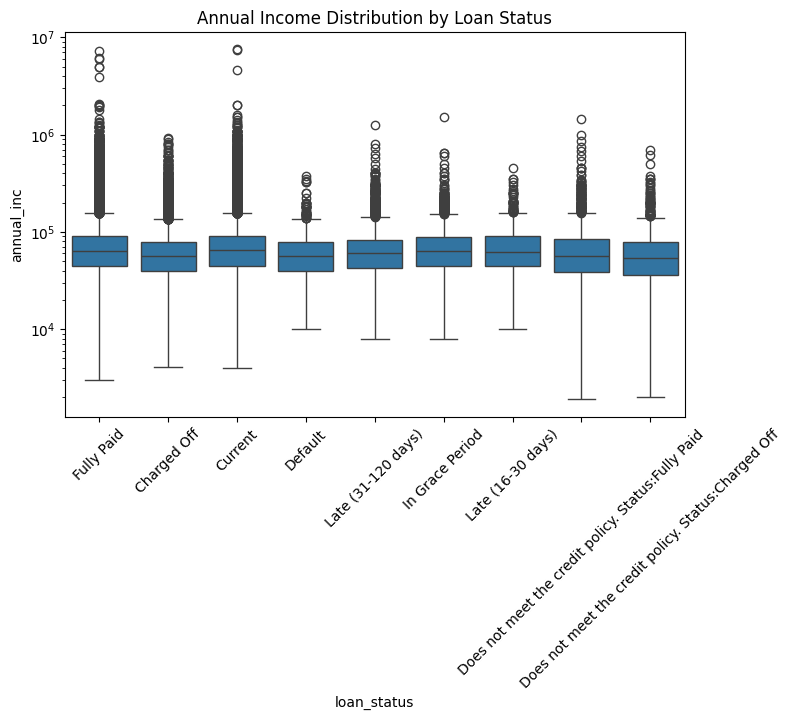

In [12]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x="loan_status",
    y="annual_inc"
)

plt.xticks(rotation=45)
plt.yscale("log")
plt.title("Annual Income Distribution by Loan Status")
plt.show()

Distribusi pendapatan tahunan menunjukkan variabilitas yang cukup besar di antara berbagai status hasil pinjaman. Meskipun pendapatan saja tidak dapat memisahkan peminjam baik dan buruk secara sempurna, peminjam dengan pendapatan lebih rendah cenderung memiliki sebaran yang lebih lebar dan paparan lebih tinggi terhadap kegagalan pembayaran.

Hal ini menunjukkan bahwa kapasitas pengembalian pinjaman tidak hanya ditentukan oleh besarnya pendapatan, melainkan juga oleh beban kewajiban finansial serta perilaku kredit peminjam.

## 5.5 Rasio Utang terhadap Pendapatan (Debt-to-Income Ratio) dan Risiko Kredit

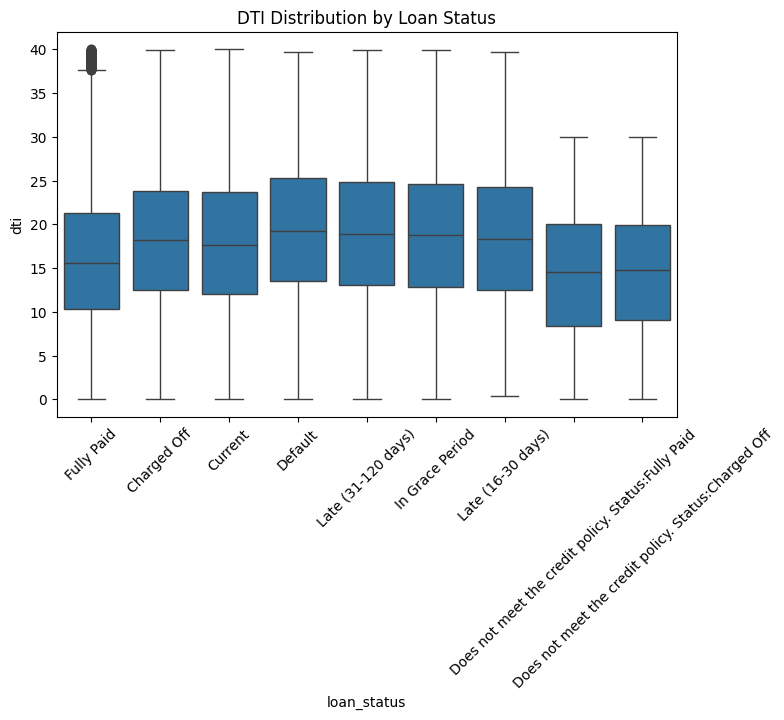

In [13]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x="loan_status",
    y="dti"
)

plt.xticks(rotation=45)
plt.title("DTI Distribution by Loan Status")
plt.show()

Rasio utang terhadap pendapatan (*Debt-to-Income* / DTI) menunjukkan pergeseran ke arah yang lebih tinggi pada pinjaman yang mengalami kesulitan pembayaran. Peminjam dengan DTI yang lebih tinggi memikul kewajiban finansial yang lebih besar dibandingkan pendapatannya, sehingga mengurangi fleksibilitas keuangan dalam melunasi pinjaman.

Temuan ini mendukung hipotesis bahwa beban finansial merupakan faktor penentu yang sangat penting terhadap risiko gagal bayar kredit.

## 5.6 Utilisasi Kredit (Credit Utilization) dan Risiko Kredit

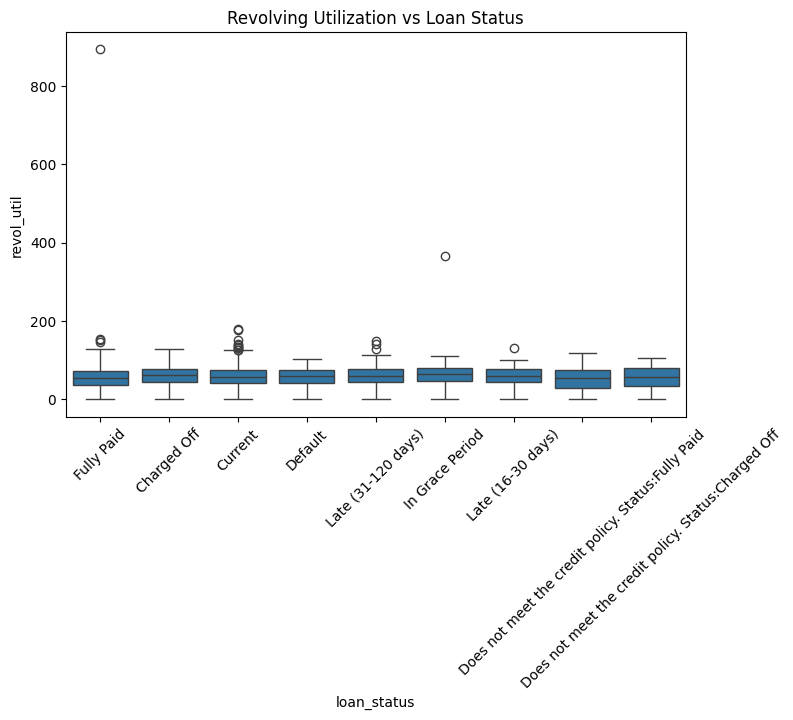

In [14]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x="loan_status",
    y="revol_util"
)

plt.xticks(rotation=45)
plt.title("Revolving Utilization vs Loan Status")
plt.show()

Tingkat utilisasi kredit berulang (*revolving credit utilization*) menunjukkan variabilitas yang lebih tinggi pada pinjaman yang menunggak dan gagal bayar. Tingkat utilisasi yang tinggi mengindikasikan bahwa peminjam sangat bergantung pada fasilitas kredit yang ada, yang dapat menjadi sinyal tekanan keuangan.

Rasio utilisasi yang tinggi umumnya diasosiasikan dengan peningkatan probabilitas gagal bayar, menjadikan fitur ini indikator krusial bagi kesehatan finansial peminjam.

# 6. Persiapan Data dan Rekayasa Fitur (Data Preparation & Feature Engineering)

## 6.1 Pembentukan Variabel Target

In [15]:
bad_status = [
    "Charged Off",
    "Default",
    "Late (31-120 days)",
    "Late (16-30 days)"
]

good_status = [
    "Fully Paid"
]

df = df[df["loan_status"].isin(bad_status + good_status)]

df["target"] = df["loan_status"].apply(
    lambda x: 1 if x in bad_status else 0
)

Untuk memungkinkan prediksi risiko kredit secara biner, status hasil pinjaman ditransformasikan menjadi variabel target klasifikasi.

Pinjaman yang dikategorikan sebagai *Charged Off*, *Default*, dan status keterlambatan pembayaran diberi label **Bad Loan (1)** yang menandakan risiko kredit tinggi. Pinjaman yang berhasil dilunasi (*Fully Paid*) diberi label **Good Loan (0)**.

Pinjaman dengan status pembayaran yang masih ambigu seperti *Current* dan *In Grace Period* dikeluarkan dari analisis untuk menghindari ketidakpastian dalam proses pembelajaran model.

## 6.2 Pemilihan dan Penghapusan Fitur

In [16]:
drop_id_cols = [
    "Unnamed: 0",
    "id",
    "member_id",
    "url"
]

df = df.drop(columns=drop_id_cols, errors="ignore")

In [17]:
leakage_cols = [
    "total_pymnt",
    "total_pymnt_inv",
    "total_rec_int",
    "recoveries",
    "collection_recovery_fee",
    "last_pymnt_amnt",
    "out_prncp",
    "out_prncp_inv"
]

df = df.drop(columns=leakage_cols, errors="ignore")

In [18]:
high_cardinality_cols = [
    "emp_title",
    "title",
    "desc"
]

df = df.drop(columns=high_cardinality_cols, errors="ignore")

Fitur-fitur yang telah diidentifikasi pada tahap penilaian kualitas data dihapus sebelum tahap pemodelan.

Variabel pengenal (*identifier*) dikeluarkan karena tidak memiliki daya prediktif. Variabel pasca-pinjaman yang memicu kebocoran data (*data leakage*) dihapus untuk menjamin skenario prediksi yang realistis. Selain itu, fitur teks dengan kardinalitas tinggi dieliminasi untuk mengurangi dimensionalitas dan mencegah *overfitting*.

## 6.3 Penanganan Nilai yang Hilang (Missing Value Treatment)

In [19]:
num_cols = df.select_dtypes(include=["int64","float64"]).columns

df[num_cols] = df[num_cols].fillna(df[num_cols].median())

In [20]:
cat_cols = df.select_dtypes(include=["object"]).columns

df[cat_cols] = df[cat_cols].fillna("Unknown")

Nilai numerik yang hilang diimputasi menggunakan nilai median guna mengurangi sensitivitas terhadap nilai ekstrem (*outlier*). Variabel kategorikal diisi dengan kategori "Unknown" untuk mempertahankan observasi tanpa menimbulkan bias buatan.

## 6.4 Encoding Fitur (Feature Encoding)

In [21]:
df = pd.get_dummies(df, drop_first=True)

Variabel kategorikal ditransformasikan menggunakan One-Hot Encoding agar kompatibel dengan algoritma machine learning sekaligus menghindari asumsi urutan (*ordinal*) antarkategori.

## 6.5 Pembagian Data Latih dan Uji (Train-Test Split)

In [22]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["target"])
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

Dataset dibagi menjadi subset data latih (*training*) dan data uji (*testing*) menggunakan *stratified sampling* untuk menjaga proporsi distribusi kelas antara pinjaman baik dan buruk. Hal ini memastikan evaluasi model yang andal pada kondisi risiko kredit yang realistis.

# 7. Pemodelan dan Benchmarking Algoritma

## 7.1 Tujuan Pemodelan
Tujuan utama dari tahap pemodelan adalah mengembangkan model prediktif yang mampu mengestimasi risiko kredit peminjam berdasarkan karakteristik finansial dan data pengajuan pinjaman. Model bertujuan mengklasifikasikan peminjam ke dalam kategori risiko kredit baik (*good*) dan buruk (*bad*) guna mendukung pengambilan keputusan persetujuan pinjaman.

Dalam lingkungan pembiayaan kredit, kesalahan dalam menyetujui peminjam berisiko tinggi dapat menimbulkan kerugian finansial yang signifikan. Oleh karena itu, evaluasi performa model tidak hanya berfokus pada kemampuan diskriminasi secara keseluruhan, tetapi juga pada efektivitas dalam mengidentifikasi peminjam berisiko.

Untuk merefleksikan berbagai strategi pembiayaan di dunia nyata, dua skenario definisi risiko diimplementasikan:

- **Definisi Risiko Konservatif (*Conservative Risk Definition*)**  
  Hanya kegagalan pembayaran yang parah seperti *Charged Off* dan *Default* yang diklasifikasikan sebagai bad loan.
- **Definisi Deteksi Risiko Dini (*Early Risk Detection Definition*)**  
  Indikator keterlambatan awal juga dianggap sebagai bad loan untuk memungkinkan mitigasi risiko secara proaktif.

Pendekatan dua definisi ini memungkinkan simulasi berbagai alternatif kebijakan persetujuan kredit.

## 7.2 Algoritma yang Dipilih

Tiga algoritma dipilih untuk tahap *benchmarking*:

### Logistic Regression
Logistic Regression berfungsi sebagai model dasar (*baseline*) yang sangat transparan dan mudah diinterpretasikan, umum digunakan dalam industri *credit scoring* karena kemudahan pemenuhan regulasi keuangannya.

### XGBoost
XGBoost merupakan algoritma *gradient boosting* yang mampu menangkap hubungan non-linear kompleks serta interaksi antarfitur, menjadikannya sangat efektif untuk dataset keuangan terstruktur (*tabular*).

### LightGBM
LightGBM menyediakan implementasi *gradient boosting* yang sangat efisien dan dioptimalkan untuk dataset berskala besar, menawarkan kecepatan pelatihan yang tinggi dengan tetap mempertahankan performa prediktif yang kuat.

## 7.3 Strategi Pelatihan Model

Sebelum pelatihan model, beberapa strategi prapemrosesan dan pelatihan diterapkan untuk memastikan proses pembelajaran yang andal:

- Label target dibentuk berdasarkan kebijakan risiko yang telah ditentukan sebelumnya.
- Variabel kebocoran data (*data leakage*) dihapus untuk mencegah pemodelan terpapar informasi masa depan.
- Variabel numerik diimputasi menggunakan nilai median.
- Variabel kategorikal di-*encode* menggunakan One-Hot Encoding.
- *Stratified sampling* diterapkan untuk mempertahankan proporsi kelas target.
- Ketidakseimbangan kelas ditangani menggunakan pembobotan kelas (*class weighting*).
- Sampel berstrata sebanyak 120.000 observasi digunakan selama tahap *benchmarking* untuk mempercepat eksperimen.

### Pembentukan Label (Label Construction)

In [23]:
def make_labels(data: pd.DataFrame, mode: str) -> pd.DataFrame:
    df_ = data.copy()
    ls = df_["loan_status"].astype(str)

    if mode == "conservative":
        good = ["Fully Paid"]
        bad  = ["Charged Off", "Default"]
    elif mode == "early_risk":
        good = ["Fully Paid"]
        bad  = ["Charged Off", "Default", "Late (16-30 days)", "Late (31-120 days)"]
    else:
        raise ValueError("mode must be 'conservative' or 'early_risk'")

    keep = good + bad
    df_ = df_[ls.isin(keep)].copy()
    df_["target_bad"] = np.where(df_["loan_status"].isin(bad), 1, 0)
    return df_

### Persiapan Fitur (Feature Preparation)

In [24]:
LEAKAGE_MIN = [
    "out_prncp","out_prncp_inv",
    "total_pymnt","total_pymnt_inv",
    "total_rec_prncp","total_rec_int","total_rec_late_fee",
    "recoveries","collection_recovery_fee",
    "last_pymnt_d","last_pymnt_amnt","next_pymnt_d",
    "last_credit_pull_d"
]
ID_COLS = ["Unnamed: 0", "id", "member_id"]
TEXT_HEAVY = ["emp_title", "title", "desc"]
HIGH_CARD = ["zip_code"]

def prepare_features(df_labeled: pd.DataFrame):
    drop_cols = [c for c in (LEAKAGE_MIN + ID_COLS + TEXT_HEAVY + HIGH_CARD) if c in df_labeled.columns]
    X = df_labeled.drop(columns=drop_cols, errors="ignore").copy()
    y = X.pop("target_bad")
    X = X.drop(columns=["loan_status"], errors="ignore")
    return X, y

### Stratified Sampling (Pengambilan Sampel Berstrata)

In [25]:
def stratified_sample(X, y, n=120_000, seed=42):
    if len(y) <= n:
        return X, y

    rng = np.random.RandomState(seed)
    idx0 = np.where(y.values == 0)[0]
    idx1 = np.where(y.values == 1)[0]

    n1 = int(n * (y.mean()))
    n1 = max(5_000, min(n1, len(idx1)))
    n0 = n - n1
    n0 = min(n0, len(idx0))

    s0 = rng.choice(idx0, size=n0, replace=False)
    s1 = rng.choice(idx1, size=n1, replace=False)

    sel = np.concatenate([s0, s1])
    rng.shuffle(sel)
    return X.iloc[sel].copy(), y.iloc[sel].copy()

### Pipeline Prapemrosesan (Preprocessing Pipeline)

In [26]:
def build_preprocessor(X, scale_numeric: bool):
    num_cols = X.select_dtypes(include=[np.number]).columns.tolist()
    cat_cols = X.select_dtypes(exclude=[np.number]).columns.tolist()

    num_steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale_numeric:
        num_steps.append(("scaler", StandardScaler()))
    num_pipe = Pipeline(num_steps)

    cat_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=True)),
    ])

    return ColumnTransformer(
        [("num", num_pipe, num_cols), ("cat", cat_pipe, cat_cols)],
        remainder="drop"
    )

## 7.4 Metrik Evaluasi

Performa model dievaluasi menggunakan beberapa metrik pelengkap:

- **ROC-AUC**: Mengukur kemampuan diskriminasi keseluruhan antara peminjam baik dan peminjam buruk.
- **PR-AUC**: Mengevaluasi performa model di bawah kondisi ketidakseimbangan kelas (*class imbalance*).
- **Precision (Bad Loan)**: Menunjukkan keakuratan prediksi terhadap peminjam yang diklasifikasikan berisiko tinggi.
- **Recall (Bad Loan)**: Mengukur kemampuan model dalam menangkap peminjam yang sebenarnya mengalami gagal bayar (*defaulters*).
- **F1-score**: Menyeimbangkan performa antara *precision* dan *recall*.

Metrik-metrik ini memastikan evaluasi selaras dengan tujuan manajemen risiko kredit di dunia nyata.

## 7.5 Pemodelan Benchmark

Fase *benchmarking* awal dilakukan untuk membandingkan performa kandidat algoritma secara efisien sebelum memilih model final untuk tahap produksi.

Guna mengurangi beban komputasi sembari tetap mempertahankan representasi distribusi kelas yang tepat, *benchmarking* dilakukan menggunakan subset berstrata (*stratified subset*) sebanyak 120.000 observasi.

In [27]:
def quick_benchmark(data, mode="early_risk", sample_n=120_000, use_xgb=True):
    d = make_labels(data, mode)
    X, y = prepare_features(d)

    X, y = stratified_sample(X, y, n=sample_n)

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y
    )

    neg = (y_train == 0).sum()
    pos = (y_train == 1).sum()
    pos_weight = float(neg / max(pos, 1))

    models = {
        "LogReg": LogisticRegression(max_iter=1500, class_weight="balanced", n_jobs=-1),
        "LightGBM": lgb.LGBMClassifier(
            n_estimators=250, learning_rate=0.05, num_leaves=31,
            subsample=0.8, colsample_bytree=0.8,
            random_state=42, n_jobs=-1
        ),
    }
    if use_xgb:
        models["XGBoost"] = xgb.XGBClassifier(
            n_estimators=200, learning_rate=0.05, max_depth=4,
            subsample=0.8, colsample_bytree=0.8,
            reg_lambda=1.0,
            objective="binary:logistic", eval_metric="auc",
            random_state=42, n_jobs=-1,
            scale_pos_weight=pos_weight
        )

    rows = []
    for name, model in models.items():
        scale_numeric = (name == "LogReg")
        prep = build_preprocessor(X_train, scale_numeric)

        pipe = Pipeline([("prep", prep), ("model", model)])
        pipe.fit(X_train, y_train)

        proba = pipe.predict_proba(X_test)[:, 1]
        pred = (proba >= 0.5).astype(int)

        rows.append({
            "mode": mode,
            "sample_n": len(y),
            "model": name,
            "bad_rate": float(y.mean()),
            "roc_auc": roc_auc_score(y_test, proba),
            "pr_auc": average_precision_score(y_test, proba),
            "precision_bad@0.5": precision_score(y_test, pred, zero_division=0),
            "recall_bad@0.5": recall_score(y_test, pred, zero_division=0),
            "f1_bad@0.5": f1_score(y_test, pred, zero_division=0),
        })

    return pd.DataFrame(rows).sort_values("roc_auc", ascending=False)

In [28]:
res_fast = quick_benchmark(df_raw, mode="early_risk", sample_n=120_000, use_xgb=True)
res_fast

[LightGBM] [Info] Number of positive: 20904, number of negative: 75096
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003733 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 4774
[LightGBM] [Info] Number of data points in the train set: 96000, number of used features: 645
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.217750 -> initscore=-1.278827
[LightGBM] [Info] Start training from score -1.278827


,mode,sample_n,model,bad_rate,roc_auc,pr_auc,precision_bad@0.5,recall_bad@0.5,f1_bad@0.5
1,early_risk,120000,LightGBM,0.21775,0.716516,0.407956,0.544554,0.105243,0.176395
2,early_risk,120000,XGBoost,0.21775,0.714514,0.405827,0.346383,0.655186,0.453180
0,early_risk,120000,LogReg,0.21775,0.707546,0.393979,0.381648,0.530042,0.443768


In [29]:
res_fast_cons = quick_benchmark(df_raw, mode="conservative", sample_n=120_000, use_xgb=True)
res_fast_cons

[LightGBM] [Info] Number of positive: 18230, number of negative: 77770
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003264 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 4766
[LightGBM] [Info] Number of data points in the train set: 96000, number of used features: 639
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.189896 -> initscore=-1.450687
[LightGBM] [Info] Start training from score -1.450687


,mode,sample_n,model,bad_rate,roc_auc,pr_auc,precision_bad@0.5,recall_bad@0.5,f1_bad@0.5
1,conservative,120000,LightGBM,0.1899,0.714665,0.363759,0.539554,0.058359,0.105326
2,conservative,120000,XGBoost,0.1899,0.712446,0.362011,0.306066,0.660816,0.418362
0,conservative,120000,LogReg,0.1899,0.701592,0.351494,0.341747,0.490127,0.402704


Hasil *benchmarking* menunjukkan bahwa model berbasis *gradient boosting* mengungguli model *baseline* Logistic Regression baik pada metrik ROC-AUC maupun PR-AUC.

XGBoost menunjukkan performa *recall* yang sangat kuat dalam mengidentifikasi *bad loan*, sementara LightGBM memberikan kemampuan diskriminasi yang kompetitif dengan efisiensi komputasi yang lebih cepat.

Hasil ini menunjukkan bahwa metode *ensemble* berbasis pohon (*tree-based ensemble*) lebih mampu menangkap pola risiko peminjam yang kompleks pada dataset ini.

## 7.6 Pemilihan Model (Model Selection)

Berdasarkan performa *benchmarking*, XGBoost dipilih sebagai model utama untuk prediksi risiko kredit karena keseimbangan yang unggul antara *recall* dan performa prediktif secara keseluruhan.

Dalam aplikasi risiko kredit, mengidentifikasi peminjam berisiko dengan benar jauh lebih krusial dibandingkan sekadar memaksimalkan akurasi keseluruhan. Oleh karena itu, pemilihan model memprioritaskan kemampuan deteksi risiko di atas peningkatan marjinal pada akurasi klasifikasi.

## 7.7 Pelatihan Model Final

Setelah pemilihan model dilakukan, algoritma terpilih dilatih kembali menggunakan dataset lengkap yang telah disiapkan untuk memperoleh prediksi probabilitas yang terkalibrasi guna optimasi kebijakan kredit.

Untuk tujuan reproduktifitas, langkah pelatihan akhir ini merekonstruksi dataset berlabel dan kumpulan fitur menggunakan fungsi persiapan yang sama seperti yang didefinisikan pada Bagian 6, kemudian melatih ulang model terpilih untuk menghasilkan output probabilitas yang digunakan dalam optimasi kebijakan.

In [30]:
MODE = "early_risk"
SAMPLE_N = 120_000

d = make_labels(df_raw, MODE)
X, y = prepare_features(d)
X, y = stratified_sample(X, y, n=SAMPLE_N)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

neg = (y_train == 0).sum()
pos = (y_train == 1).sum()
pos_weight = float(neg / max(pos, 1))

prep_lr  = build_preprocessor(X_train, scale_numeric=True)
prep_tree = build_preprocessor(X_train, scale_numeric=False)

Melatih XGBoost + Logistic Regression

In [31]:
lr = LogisticRegression(max_iter=1500, class_weight="balanced", n_jobs=-1)

xgb_model = xgb.XGBClassifier(
    n_estimators=250, learning_rate=0.05, max_depth=4,
    subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0,
    objective="binary:logistic", eval_metric="auc",
    random_state=42, n_jobs=-1, scale_pos_weight=pos_weight
)

pipe_lr = Pipeline([("prep", prep_lr), ("model", lr)])
pipe_xgb = Pipeline([("prep", prep_tree), ("model", xgb_model)])

pipe_lr.fit(X_train, y_train)
pipe_xgb.fit(X_train, y_train)

proba_lr  = pipe_lr.predict_proba(X_test)[:, 1]
proba_xgb = pipe_xgb.predict_proba(X_test)[:, 1]

print("LR  ROC-AUC:", roc_auc_score(y_test, proba_lr), "PR-AUC:", average_precision_score(y_test, proba_lr))
print("XGB ROC-AUC:", roc_auc_score(y_test, proba_xgb), "PR-AUC:", average_precision_score(y_test, proba_xgb))

LR  ROC-AUC: 0.7075457357687148 PR-AUC: 0.3939792068168737
XGB ROC-AUC: 0.7151800001394313 PR-AUC: 0.4072892159129463


# 8. Optimasi Ambang Batas (Threshold Optimization)

Setelah melatih model prediktif akhir, output probabilitas dianalisis untuk menentukan ambang batas keputusan (*decision threshold*) yang optimal.
Alih-alih mengandalkan ambang batas klasifikasi default (0,5), optimasi *threshold* memungkinkan model menyelaraskan keputusan prediksi dengan toleransi risiko bisnis dan tujuan kebijakan pembiayaan.

Dalam pemodelan risiko kredit, *threshold* yang berbeda menghasilkan *trade-off* yang berbeda antara:

- Kemampuan deteksi risiko (*recall* terhadap peminjam berisiko)
- Tingkat persetujuan pinjaman (*approval rate*)
- Kualitas portofolio kredit

Oleh karena itu, beberapa skenario *threshold* dievaluasi.

## 8.1 Pembuatan Laporan Performa Threshold

Probabilitas prediksi yang dihasilkan oleh model yang telah dilatih dievaluasi pada berbagai nilai *threshold*.
Untuk setiap *threshold*, beberapa indikator performa dihitung:

- *Precision* (Kelas Bad)
- *Recall* (Deteksi Risiko)
- *F1-score*
- Tingkat Persetujuan (*Approval Rate*)
- Tingkat Gagal Bayar di Antara Pinjaman yang Disetujui (*Bad Rate Among Approved Loans*)

Analisis ini memungkinkan kita memahami bagaimana keputusan pemberian pinjaman berubah di bawah tingkat toleransi risiko yang berbeda.

In [32]:
def threshold_report(y_true, proba, thresholds=None):
    if thresholds is None:
        thresholds = np.linspace(0.05, 0.95, 19)

    rows = []
    y_true = np.asarray(y_true)

    for t in thresholds:
        pred = (proba >= t).astype(int)

        precision = precision_score(y_true, pred, zero_division=0)
        recall    = recall_score(y_true, pred, zero_division=0)
        f1        = f1_score(y_true, pred, zero_division=0)

        approval_rate = float((pred == 0).mean())
        bad_caught    = float(((pred == 1) & (y_true == 1)).sum() / max((y_true == 1).sum(), 1))

        approved_mask = (pred == 0)
        if approved_mask.sum() > 0:
            bad_rate_approved = float((y_true[approved_mask] == 1).mean())
        else:
            bad_rate_approved = np.nan

        rows.append({
            "threshold": float(t),
            "precision_bad": float(precision),
            "recall_bad": float(recall),
            "f1_bad": float(f1),
            "approval_rate": float(approval_rate),
            "bad_caught_rate": float(bad_caught),
            "bad_rate_among_approved": float(bad_rate_approved)
        })

    return pd.DataFrame(rows)

In [33]:
thr_lr  = threshold_report(y_test, proba_lr)
thr_xgb = threshold_report(y_test, proba_xgb)

thr_lr.head(), thr_xgb.head()

(   threshold  precision_bad  recall_bad    f1_bad  approval_rate  \
 0       0.05       0.218613    0.999235  0.358740       0.004708   
 1       0.10       0.223845    0.994068  0.365408       0.033000   
 2       0.15       0.234563    0.982013  0.378676       0.088375   
 3       0.20       0.248408    0.955224  0.394282       0.162667   
 4       0.25       0.264259    0.906047  0.409177       0.253417   
 
    bad_caught_rate  bad_rate_among_approved  
 0         0.999235                 0.035398  
 1         0.994068                 0.039141  
 2         0.982013                 0.044319  
 3         0.955224                 0.059939  
 4         0.906047                 0.080730  ,
    threshold  precision_bad  recall_bad    f1_bad  approval_rate  \
 0       0.05       0.217759    1.000000  0.357639       0.000042   
 1       0.10       0.219920    0.999235  0.360498       0.010625   
 2       0.15       0.225883    0.995599  0.368224       0.040250   
 3       0.20       0.234

## 8.2 Pemilihan Threshold Berorientasi Risiko (Risk-Oriented Threshold Selection)

Pada skenario ini, tujuannya adalah memaksimalkan deteksi peminjam berisiko dengan tetap mempertahankan tingkat *precision* prediksi yang dapat diterima.

Strategi ini memprioritaskan minimalisasi paparan risiko gagal bayar (*default risk*).

In [34]:
def pick_threshold(df_thr, min_precision=0.35):
    cand = df_thr[df_thr["precision_bad"] >= min_precision].copy()
    if len(cand) == 0:
        return df_thr.sort_values("f1_bad", ascending=False).head(1)
    return cand.sort_values("recall_bad", ascending=False).head(1)

best_lr  = pick_threshold(thr_lr,  min_precision=0.35)
best_xgb = pick_threshold(thr_xgb, min_precision=0.35)

print("Best LR threshold:")
display(best_lr)

print("Best XGB threshold:")
display(best_xgb)

Best LR threshold:


,threshold,precision_bad,recall_bad,f1_bad,approval_rate,bad_caught_rate,bad_rate_among_approved
8,0.45,0.353461,0.612706,0.448302,0.622542,0.612706,0.135466


Best XGB threshold:


,threshold,precision_bad,recall_bad,f1_bad,approval_rate,bad_caught_rate,bad_rate_among_approved
10,0.55,0.379966,0.561806,0.453331,0.678042,0.561806,0.140724


## 8.3 Pemilihan Threshold Berorientasi Kebijakan (Policy-Oriented Threshold Selection)

Dari perspektif bisnis, pemberi pinjaman mungkin memprioritaskan penjagaan tingkat gagal bayar yang rendah di antara peminjam yang disetujui, meskipun jumlah pinjaman yang disetujui menjadi lebih sedikit.

Pendekatan ini mensimulasikan kebijakan pinjaman yang konservatif.

In [35]:
def pick_policy_threshold(df_thr, max_bad_rate_approved=0.12):
    cand = df_thr[df_thr["bad_rate_among_approved"] <= max_bad_rate_approved].copy()
    if len(cand) == 0:
        return df_thr.sort_values("bad_rate_among_approved", ascending=True).head(1)
    return cand.sort_values("approval_rate", ascending=False).head(1)

policy_lr  = pick_policy_threshold(thr_lr,  max_bad_rate_approved=0.12)
policy_xgb = pick_policy_threshold(thr_xgb, max_bad_rate_approved=0.12)

display(policy_lr)
display(policy_xgb)

,threshold,precision_bad,recall_bad,f1_bad,approval_rate,bad_caught_rate,bad_rate_among_approved
6,0.35,0.304793,0.775163,0.437544,0.446208,0.775163,0.109721


,threshold,precision_bad,recall_bad,f1_bad,approval_rate,bad_caught_rate,bad_rate_among_approved
8,0.45,0.323485,0.737467,0.449708,0.503583,0.737467,0.11352


## 8.4 Pemetaan dan Ringkasan Kebijakan Berdasarkan Threshold

Dari perspektif bisnis, pemberi pinjaman dapat memetakan metrik-metrik utama di berbagai ambang batas guna mengevaluasi dampak kebijakan pinjaman secara komprehensif.

In [36]:
def policy_table(df_thr):
    cols = ["threshold","approval_rate","bad_rate_among_approved","recall_bad","precision_bad","f1_bad"]
    return df_thr[cols].copy()

print("XGB policy sweep (top 10 by lowest bad_rate among approved):")
display(policy_table(thr_xgb).sort_values("bad_rate_among_approved").head(10))

print("XGB policy sweep (top 10 by highest recall):")
display(policy_table(thr_xgb).sort_values("recall_bad", ascending=False).head(10))

XGB policy sweep (top 10 by lowest bad_rate among approved):


,threshold,approval_rate,bad_rate_among_approved,recall_bad,precision_bad,f1_bad
0,0.05,0.000042,0.000000,1.000000,0.217759,0.357639
1,0.10,0.010625,0.015686,0.999235,0.219920,0.360498
2,0.15,0.040250,0.023810,0.995599,0.225883,0.368224
3,0.20,0.084583,0.040394,0.984309,0.234137,0.378291
4,0.25,0.145625,0.053505,0.964217,0.245745,0.391668
5,0.30,0.227542,0.068669,0.928243,0.261665,0.408247
6,0.35,0.319208,0.088761,0.869881,0.278230,0.421609
7,0.40,0.412083,0.103539,0.804057,0.297803,0.434630
8,0.45,0.503583,0.113520,0.737467,0.323485,0.449708
9,0.50,0.590375,0.127955,0.653081,0.347167,0.453344


XGB policy sweep (top 10 by highest recall):


,threshold,approval_rate,bad_rate_among_approved,recall_bad,precision_bad,f1_bad
0,0.05,0.000042,0.000000,1.000000,0.217759,0.357639
1,0.10,0.010625,0.015686,0.999235,0.219920,0.360498
2,0.15,0.040250,0.023810,0.995599,0.225883,0.368224
3,0.20,0.084583,0.040394,0.984309,0.234137,0.378291
4,0.25,0.145625,0.053505,0.964217,0.245745,0.391668
5,0.30,0.227542,0.068669,0.928243,0.261665,0.408247
6,0.35,0.319208,0.088761,0.869881,0.278230,0.421609
7,0.40,0.412083,0.103539,0.804057,0.297803,0.434630
8,0.45,0.503583,0.113520,0.737467,0.323485,0.449708
9,0.50,0.590375,0.127955,0.653081,0.347167,0.453344


# 9. Simulasi Kebijakan Risiko (Risk Policy Simulation)

Setelah menentukan ambang batas klasifikasi yang optimal, langkah berikutnya adalah mensimulasikan keputusan pemberian pinjaman di bawah berbagai kebijakan persetujuan kredit.

Alih-alih hanya mengevaluasi akurasi model, tahap ini menerjemahkan prediksi model ke dalam dampak pinjaman di dunia nyata, seperti:

- Tingkat persetujuan pinjaman (*Loan approval rate*)
- Paparan risiko (*Risk exposure*)
- Ekspektasi kualitas portofolio kredit

Simulasi ini membantu pengambil keputusan memahami bagaimana ambang batas model memengaruhi kinerja bisnis secara langsung.

## 9.1 Logika Keputusan Kebijakan

Dalam aplikasi risiko kredit, prediksi diubah menjadi keputusan pinjaman menggunakan aturan berikut:

- Prediksi peminjam BAIK (*GOOD* - 0) → Pinjaman Disetujui (*Approved*)
- Prediksi peminjam BURUK (*BAD* - 1) → Pinjaman Ditolak (*Rejected*)

Ambang batas yang berbeda secara langsung memengaruhi:

- Jumlah peminjam yang disetujui
- Risiko gagal bayar di dalam kelompok pinjaman yang disetujui
- Kemampuan deteksi risiko secara keseluruhan

## 9.2 Simulasi Keputusan Persetujuan Pinjaman

Dengan menggunakan *threshold* yang dipilih, keputusan persetujuan peminjam disimulasikan berdasarkan probabilitas prediksi model.

In [37]:
def simulate_policy(y_true, proba, threshold):
    pred = (proba >= threshold).astype(int)
    approval_mask = (pred == 0)
    approval_rate = approval_mask.mean()

    if approval_mask.sum() > 0:
        bad_rate_approved = (
            (y_true[approval_mask] == 1).mean()
        )
    else:
        bad_rate_approved = np.nan

    bad_caught_rate = (
        ((pred == 1) & (y_true == 1)).sum()
        / max((y_true == 1).sum(), 1)
    )

    return {
        "threshold": threshold,
        "approval_rate": float(approval_rate),
        "bad_rate_among_approved": float(bad_rate_approved),
        "bad_caught_rate": float(bad_caught_rate)
    }

## 9.3 Simulasi Kebijakan Berfokus pada Risiko (Risk-Focused Policy)

In [38]:
risk_thr = float(best_xgb["threshold"])

risk_policy = simulate_policy(
    y_test,
    proba_xgb,
    risk_thr
)

risk_policy

{'threshold': 0.5499999999999999,
 'approval_rate': 0.6780416666666667,
 'bad_rate_among_approved': 0.14072389848214834,
 'bad_caught_rate': 0.561806352851129}

Tingkat persetujuan yang lebih rendah diperkirakan terjadi di bawah kebijakan ini karena model secara agresif menyaring pemohon yang berisiko.

## 9.4 Simulasi Kebijakan Pinjaman Konservatif (Conservative Lending Policy)

In [39]:
policy_thr = float(policy_xgb["threshold"])

conservative_policy = simulate_policy(
    y_test,
    proba_xgb,
    policy_thr
)

conservative_policy

{'threshold': 0.44999999999999996,
 'approval_rate': 0.5035833333333334,
 'bad_rate_among_approved': 0.11351977494621876,
 'bad_caught_rate': 0.7374665135859165}

Strategi ini memastikan kualitas portofolio yang lebih tinggi, namun dapat menurunkan volume pinjaman yang disalurkan.

## 9.5 Perbandingan Kebijakan

Berbagai kebijakan pinjaman kini dapat dibandingkan secara langsung.

In [40]:
policy_compare = pd.DataFrame([
    {"policy": "Risk Detection", **risk_policy},
    {"policy": "Conservative Approval", **conservative_policy}
])

policy_compare

,policy,threshold,approval_rate,bad_rate_among_approved,bad_caught_rate
0,Risk Detection,0.55,0.678042,0.140724,0.561806
1,Conservative Approval,0.45,0.503583,0.113520,0.737467


## 9.6 Wawasan Bisnis (Business Insight)

Simulasi kebijakan risiko membuktikan bahwa penilaian kredit berbasis *machine learning* dapat secara efektif menyeimbangkan volume persetujuan pinjaman dan eksposur risiko portofolio.

Proses optimasi *threshold* menunjukkan bahwa ambang batas persetujuan yang lebih ketat secara signifikan mengurangi proporsi peminjam berisiko tinggi yang masuk ke dalam portofolio. Namun, *threshold* yang terlalu konservatif dapat menurunkan tingkat persetujuan secara drastis, sehingga berpotensi membatasi pertumbuhan bisnis. Oleh karena itu, ambang batas keputusan yang optimal harus menjaga keseimbangan antara mitigasi risiko dan peluang penyaluran pinjaman.

Dari hasil simulasi kebijakan, meningkatkan sensitivitas penolakan meningkatkan kemampuan model untuk menangkap peminjam berisiko (*recall* yang lebih tinggi untuk *bad loan*), sembari tetap menjaga kualitas persetujuan yang dapat diterima. Ini mengindikasikan bahwa pemodelan prediktif memungkinkan pengendalian risiko secara proaktif dan bukan pengelolaan kerugian yang reaktif.

Analisis keterjelasan (*explainability*) model lebih lanjut mengungkapkan bahwa indikator kesehatan finansial peminjam memegang peranan dominan dalam prediksi risiko. Variabel yang berkaitan dengan beban kredit dan kapasitas pembayaran secara konsisten muncul sebagai prediktor yang paling berpengaruh. Secara khusus:

- Rasio utang terhadap pendapatan (*DTI*) yang lebih tinggi berkaitan erat dengan peningkatan probabilitas gagal bayar.
- Tingkat utilisasi kredit berulang yang meningkat mencerminkan tekanan finansial yang lebih besar.
- Suku bunga yang lebih tinggi sering kali mencerminkan tingkat risiko peminjam yang telah dinilai sebelumnya.
- Peringkat kredit (*credit grade*) yang lebih rendah menunjukkan asosiasi yang lebih kuat dengan kegagalan pembayaran.

Temuan-temuan ini mengonfirmasi bahwa model menangkap pola perilaku pinjaman yang bermakna secara ekonomi, bukan sekadar derau statistik.

Dari perspektif bisnis, kerangka pemodelan yang diusulkan memungkinkan institusi keuangan bertransformasi dari sistem persetujuan berbasis aturan kaku (*rule-based*) menuju kebijakan kredit berbasis data yang dinamis. Dengan menyesuaikan *threshold* persetujuan secara fleksibel, pemberi pinjaman dapat mensimulasikan berbagai strategi penyaluran kredit, seperti pertumbuhan agresif, ekspansi seimbang, atau pengendalian risiko yang konservatif.

Secara keseluruhan, integrasi pemodelan prediktif dan simulasi kebijakan memberikan *trade-off* yang transparan dan terukur antara profitabilitas dan risiko kredit bagi para pengambil keputusan, guna mendukung strategi pemberian pinjaman yang lebih tepat sasaran dan adaptif.

# 10. Keterjelasan Model (Model Explainability)

Bagian ini menjelaskan bagaimana model yang telah dilatih membuat prediksi dan mengidentifikasi fitur-fitur yang paling berpengaruh terhadap penilaian risiko kredit.

## 10.1 Ekstraksi Nama Fitur

In [41]:
def get_feature_names_from_preprocessor(preprocessor, X):
    num_cols = X.select_dtypes(include=[np.number]).columns.tolist()
    cat_cols = X.select_dtypes(exclude=[np.number]).columns.tolist()

    ohe = preprocessor.named_transformers_["cat"].named_steps["ohe"]
    cat_feature_names = ohe.get_feature_names_out(cat_cols)

    feature_names = np.concatenate([np.array(num_cols, dtype=object), cat_feature_names.astype(object)])
    return feature_names

prep_fitted = pipe_xgb.named_steps["prep"]
feature_names = get_feature_names_from_preprocessor(prep_fitted, X_train)

len(feature_names), feature_names[:10]

(96862,
 array(['loan_amnt', 'funded_amnt', 'funded_amnt_inv', 'int_rate',
        'installment', 'annual_inc', 'dti', 'delinq_2yrs',
        'inq_last_6mths', 'mths_since_last_delinq'], dtype=object))

In [42]:
prep_fitted = pipe_xgb.named_steps["prep"]

feature_names = prep_fitted.get_feature_names_out()

print("n_features (names):", len(feature_names))
print("n_features (model):", len(pipe_xgb.named_steps["model"].feature_importances_))

n_features (names): 96845
n_features (model): 96845


Nama-nama fitur diekstraksi setelah prapemrosesan untuk menginterpretasikan variabel yang telah di-*encode* dengan benar.

## 10.2 Kepentingan Fitur Global (Global Feature Importance)

In [43]:
importances = pipe_xgb.named_steps["model"].feature_importances_

fi = pd.DataFrame({
    "feature": feature_names,
    "importance": importances
}).sort_values("importance", ascending=False)

fi.head(20)

,feature,importance
25,cat__grade_A,0.114305
3,num__int_rate,0.053912
24,cat__term_ 60 months,0.047401
23,cat__term_ 36 months,0.032438
26,cat__grade_B,0.027566
28,cat__grade_D,0.020283
27,cat__grade_C,0.019262
6,num__dti,0.009110
5,num__annual_inc,0.008016
43,cat__sub_grade_C2,0.007055


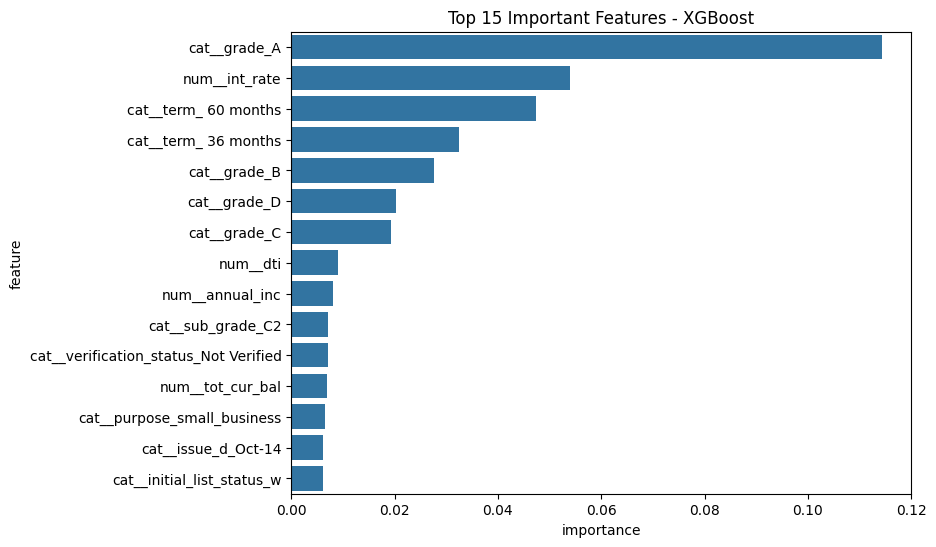

In [44]:
plt.figure(figsize=(8,6))

sns.barplot(
    data=fi.head(15),
    x="importance",
    y="feature"
)

plt.title("Top 15 Important Features - XGBoost")
plt.show()

Analisis *feature importance* menunjukkan bahwa indikator beban finansial seperti rasio utang terhadap pendapatan (*DTI*) dan utilisasi kredit sangat memengaruhi prediksi gagal bayar.

## 10.3 Penjelasan Global SHAP (SHAP Global Explanation)

In [45]:
sample_size = 2000

idx = np.random.choice(
    X_train.shape[0],
    sample_size,
    replace=False
)

X_sample = X_train.iloc[idx]

In [46]:
X_sample_transformed = prep_fitted.transform(X_sample)

In [47]:

model_only = pipe_xgb.named_steps["model"]

explainer = shap.TreeExplainer(model_only)

NameError: name 'shap' is not defined

In [ ]:
shap_values = explainer.shap_values(X_sample_transformed)

In [ ]:
shap.summary_plot(
    shap_values,
    X_sample_transformed,
    feature_names=feature_names
)

Analisis SHAP menunjukkan bagaimana nilai-nilai fitur meningkatkan atau menurunkan prediksi risiko kredit di seluruh populasi peminjam.

## 10.4 Penjelasan Prediksi Lokal (Local Prediction Explanation)

In [ ]:
i = 0

x_row = X_sample_transformed[i]
if hasattr(x_row, "toarray"):
    x_row = x_row.toarray().ravel()
else:
    x_row = np.asarray(x_row).ravel()

sv_row = shap_values[i]

shap.force_plot(
    explainer.expected_value,
    sv_row,
    x_row,
    feature_names=feature_names,
    matplotlib=True
)

Analisis *explainability* mengonfirmasi bahwa model terutama bertumpu pada karakteristik peminjam yang bermakna secara finansial seperti beban utang, utilisasi kredit, dan peringkat kredit. Baik penjelasan global maupun lokal menunjukkan hubungan yang konsisten antara indikator tekanan finansial peminjam dan probabilitas gagal bayar yang diprediksi, mengindikasikan bahwa model berhasil menangkap pola risiko kredit yang dapat diinterpretasikan secara ekonomi.

# 11. Kesimpulan (Conclusion)

Tujuan dari proyek ini adalah mengembangkan kerangka kerja prediksi risiko kredit *end-to-end* yang mampu mendukung pengambilan keputusan pemberian pinjaman berbasis data. Dengan memanfaatkan data historis kinerja pinjaman, solusi berbasis *machine learning* dibangun untuk mengidentifikasi peminjam dengan risiko gagal bayar yang tinggi sembari mempertahankan transparansi operasional dan kemudahan interpretasi bisnis.

Analisis diawali dengan pemahaman data dan penilaian kualitas data yang komprehensif, dilanjutkan dengan analisis eksplorasi data (EDA) untuk mengidentifikasi pola perilaku finansial peminjam dan hasil pembayaran pinjaman. Prosedur persiapan data diterapkan untuk menangani nilai yang hilang, menghapus potensi kebocoran data (*data leakage*), serta membentuk variabel target yang andal untuk merepresentasikan status risiko kredit.

Beberapa algoritma *machine learning* dievaluasi pada tahap *benchmarking*, termasuk Logistic Regression dan model berbasis *gradient boosting*. Evaluasi komparatif menunjukkan bahwa metode *ensemble* berbasis pohon, khususnya XGBoost, memberikan performa prediktif yang lebih unggul dalam menangkap hubungan non-linear pada atribut keuangan peminjam. Oleh karena itu, XGBoost dipilih sebagai model kandidat produksi final.

Alih-alih hanya mengandalkan akurasi klasifikasi, optimasi ambang batas (*threshold optimization*) dilakukan guna menyelaraskan prediksi model dengan tujuan bisnis pembiayaan. Proses ini memungkinkan penyesuaian yang fleksibel antara kemampuan deteksi risiko dan volume persetujuan pinjaman. Simulasi kebijakan lebih lanjut menerjemahkan output model ke dalam skenario pinjaman dunia nyata, memperlihatkan bagaimana variasi *threshold* secara langsung memengaruhi tingkat persetujuan dan eksposur risiko portofolio.

Analisis *explainability* mengonfirmasi bahwa prediksi model didorong oleh variabel-variabel yang bermakna secara ekonomi. Indikator beban finansial seperti rasio utang terhadap pendapatan (*debt-to-income*), utilisasi kredit berulang (*revolving credit utilization*), suku bunga, dan peringkat kredit muncul sebagai kontributor dominan dalam memprediksi gagal bayar. Baik teknik penjelasan global maupun lokal memverifikasi bahwa perilaku model selaras dengan prinsip-prinsip risiko kredit yang telah mapan, sehingga meningkatkan kepercayaan dan interpretabilitas.

Secara keseluruhan, kerangka kerja yang diusulkan menggambarkan bagaimana *machine learning* dapat meningkatkan proses evaluasi kredit konvensional dengan mentransformasikan data historis pinjaman menjadi sistem pendukung keputusan yang dapat ditindaklanjuti. Dengan mengintegrasikan pemodelan prediktif, optimasi *threshold*, simulasi kebijakan, dan analisis keterjelasan model, solusi ini memungkinkan institusi keuangan menyeimbangkan ambisi pertumbuhan bisnis dengan persyaratan mitigasi risiko.

Dalam penerapannya di dunia nyata, model ini dapat mendukung strategi pinjaman adaptif dengan menyesuaikan ambang batas persetujuan secara dinamis sesuai dengan selera risiko institusi dan kondisi pasar. Pengembangan di masa depan dapat mencakup pelatihan ulang model secara berkala, pemantauan *data drift*, serta penambahan indikator makroekonomi untuk semakin memperkuat ketahanan prediktif.

Proyek ini mendemonstrasikan keberhasilan implementasi siklus hidup *data science* yang lengkap, mulai dari analisis data mentah hingga penyediaan pendukung keputusan yang berorientasi pada bisnis, sehingga meletakkan fondasi yang kokoh dan terukur bagi pengelolaan risiko kredit yang cerdas.